In [34]:
# Cell 0: Imports, paths, and CPA scoring function

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import time

def cpa_scores(H, T):
    """
    Maximum absolute Pearson correlation across samples,
    for each of the 256 key guesses.
    H: (N, 256)
    T: (N, samples)
    """
    H = np.asarray(H, dtype=np.float64)
    T = np.asarray(T, dtype=np.float64)

    if H.ndim != 2 or H.shape[1] != 256:
        raise ValueError(f"Expected H=(N,256), got {H.shape}")
    if T.ndim != 2 or H.shape[0] != T.shape[0]:
        raise ValueError(f"Incompatible H and T: {H.shape}, {T.shape}")
    if len(T) < 2:
        raise ValueError("At least two traces are required.")

    Hc = H - H.mean(axis=0, keepdims=True)
    Tc = T - T.mean(axis=0, keepdims=True)

    numerator = Hc.T @ Tc
    denominator = np.sqrt(
        np.sum(Hc**2, axis=0)[:, None]
        * np.sum(Tc**2, axis=0)[None, :]
    )

    corr = np.divide(
        numerator,
        denominator,
        out=np.zeros_like(numerator),
        where=denominator > 0
    )

    return np.max(np.abs(corr), axis=1)

print("CPA score function ready.")

CPA score function ready.


In [46]:
from pathlib import Path

def locate_file(relative_path):
    for base in (Path.cwd(), Path.cwd().parent):
        if (base / relative_path).exists():
            return (base / relative_path).resolve()
    raise FileNotFoundError(f"Could not find {relative_path} from {Path.cwd()}")

PREPROCESSED_PATH = locate_file("results/preprocessing/preprocessed_data.npz")
HYPOTHESES_PATH   = locate_file("results/leakage_model/hd_hypotheses.npz")
print(PREPROCESSED_PATH); print(HYPOTHESES_PATH)

D:\PROJECTS\SIdeChannel\aesSca\notebooks\results\preprocessing\preprocessed_data.npz
D:\PROJECTS\SIdeChannel\aesSca\notebooks\results\leakage_model\hd_hypotheses.npz


In [35]:
#loading traces, hypotheses, fake key

with np.load(PREPROCESSED_PATH) as data:
    ciphertexts = data["ciphertexts"]
    traces = data["traces"]

print("Ciphertexts:", ciphertexts.shape)
print("Traces:", traces.shape)

# Load the recovered key from the existing result file if available.
key_path = PREPROCESSED_PATH.parent.parent / "cpa" / "fake_round10_key.txt"

if key_path.exists():
    key_hex = key_path.read_text().strip()
    FAKE_KEY = np.frombuffer(bytes.fromhex(key_hex), dtype=np.uint8)
else:
    FAKE_KEY = np.array([
        0x91, 0xDE, 0xC0, 0x68,
        0xE3, 0xFA, 0xCE, 0x45,
        0x99, 0xCE, 0x38, 0xF4,
        0x20, 0x86, 0x3A, 0x30
    ], dtype=np.uint8)

assert traces.ndim == 2 and traces.shape[1] == 200
assert ciphertexts.shape[0] == traces.shape[0]
assert FAKE_KEY.shape == (16,)

print("Number of traces:", f"{len(traces):,}")
print("Samples per trace:", traces.shape[1])
print("Fake round-10 key:", " ".join(f"{b:02X}" for b in FAKE_KEY))

Ciphertexts: (100000, 16)
Traces: (100000, 200)
Number of traces: 100,000
Samples per trace: 200
Fake round-10 key: 91 DE C0 68 E3 FA CE 45 99 CE 38 F4 20 86 3A 30


In [15]:
#CPA sample window,batch size
N = len(traces)

# Match the original CPA notebook: search all 200 samples.
SAMPLE_WINDOW = slice(0, 200)

# Initial coarse scan: test every 1,000 traces.
COARSE_STEP = 1000

# Later fine-grained scan: test every 50 traces.
FINE_STEP = 50

# Process the traces in blocks of 50 for cumulative calculations.
BATCH_SIZE = 50

# A key byte must rank first uniquely at every checkpoint
# from the candidate minimum through the end of the scan.
print("Coarse interval:", COARSE_STEP)
print("Fine interval:", FINE_STEP)
print("Samples used:", len(np.arange(traces.shape[1])[SAMPLE_WINDOW]))

Coarse interval: 1000
Fine interval: 50
Samples used: 200


In [36]:
#incremental CPA calculation
# Cell 4: Incremental CPA scoring

def correlation_scores_from_sums(
    n, sum_h, sum_h2, sum_t, sum_t2, sum_ht
):
    """
    Calculate one maximum absolute Pearson correlation score
    for each of the 256 key guesses.
    """
    cov = sum_ht - np.outer(sum_h, sum_t) / n

    var_h = np.maximum(sum_h2 - (sum_h ** 2) / n, 0.0)
    var_t = np.maximum(sum_t2 - (sum_t ** 2) / n, 0.0)

    denom = np.sqrt(np.outer(var_h, var_t))

    corr = np.divide(
        cov,
        denom,
        out=np.zeros_like(cov),
        where=denom > 0
    )

    return np.max(np.abs(corr), axis=1)


def scan_one_byte(H, T, checkpoints, batch_size=50):
    """
    Incremental CPA scan that records every requested checkpoint exactly.
    H shape: (N, 256)
    T shape: (N, samples)
    """
    H = np.asarray(H)
    T = np.asarray(T, dtype=np.float64)

    if H.shape != (len(T), 256):
        raise ValueError(
            f"Expected H shape ({len(T)}, 256), got {H.shape}"
        )

    checkpoints = sorted(set(int(n) for n in checkpoints))

    if not checkpoints or checkpoints[0] < 2:
        raise ValueError("Checkpoints must start at 2 or greater.")
    if checkpoints[-1] > len(T):
        raise ValueError("A checkpoint exceeds the available trace count.")

    sum_h = np.zeros(256, dtype=np.float64)
    sum_h2 = np.zeros(256, dtype=np.float64)
    sum_t = np.zeros(T.shape[1], dtype=np.float64)
    sum_t2 = np.zeros(T.shape[1], dtype=np.float64)
    sum_ht = np.zeros((256, T.shape[1]), dtype=np.float64)

    results = {}
    start = 0

    for target in checkpoints:
        while start < target:
            end = min(start + batch_size, target)

            hb = H[start:end].astype(np.float64, copy=False)
            tb = T[start:end]

            sum_h += hb.sum(axis=0)
            sum_h2 += np.square(hb).sum(axis=0)
            sum_t += tb.sum(axis=0)
            sum_t2 += np.square(tb).sum(axis=0)
            sum_ht += hb.T @ tb

            start = end

        results[target] = correlation_scores_from_sums(
            target, sum_h, sum_h2, sum_t, sum_t2, sum_ht
        )

    return results

print("Incremental CPA scan updated.")

Incremental CPA scan updated.


In [38]:
# Cell 5: Coarse scan in original trace order

# Cell 4: Reusable CPA scan for ordered or shuffled trace subsets

def run_all_bytes(
    checkpoints,
    indices=None,
    sample_window=slice(0, 200),
    label="CPA"
):
    if indices is None:
        indices = np.arange(len(traces))
    else:
        indices = np.asarray(indices, dtype=int)

    if len(indices) == 0:
        raise ValueError("No trace indices supplied.")

    checkpoints = sorted(set(int(n) for n in checkpoints))

    if checkpoints[-1] > len(indices):
        raise ValueError("Checkpoint exceeds the selected trace count.")

    T = np.asarray(
        traces[indices][:, sample_window],
        dtype=np.float64
    )

    all_results = {}

    with np.load(HYPOTHESES_PATH) as hypotheses:
        for b in range(16):
            print(f"{label}: byte {b}/15", flush=True)

            H = np.asarray(hypotheses[f"byte_{b}"])

            # Saved hypotheses should normally be (N, 256).
            if H.shape == (256, len(traces)):
                H = H.T

            if H.shape != (len(traces), 256):
                raise ValueError(
                    f"byte_{b} has unexpected shape {H.shape}"
                )

            H_selected = H[indices]

            all_results[b] = scan_one_byte(
                H_selected,
                T,
                checkpoints,
                batch_size=BATCH_SIZE
            )

    return all_results

print("Reusable CPA scan ready.")


coarse_checkpoints = list(range(COARSE_STEP, N + 1, COARSE_STEP))
if N not in coarse_checkpoints:
    coarse_checkpoints.append(N)

start_time = time.time()

ordered_coarse = run_all_bytes(
    checkpoints=coarse_checkpoints,
    label="Ordered"
)

print(f"\nOrdered scan finished in {(time.time() - start_time)/60:.1f} minutes.")

Reusable CPA scan ready.
Ordered: byte 0/15
Ordered: byte 1/15
Ordered: byte 2/15
Ordered: byte 3/15
Ordered: byte 4/15
Ordered: byte 5/15
Ordered: byte 6/15
Ordered: byte 7/15
Ordered: byte 8/15
Ordered: byte 9/15
Ordered: byte 10/15
Ordered: byte 11/15
Ordered: byte 12/15
Ordered: byte 13/15
Ordered: byte 14/15
Ordered: byte 15/15

Ordered scan finished in 0.7 minutes.


In [39]:
#minimum traces
# Cell 6: Evaluate key recovery at every checkpoint

# Cell 5: Evaluate complete-key recovery and correct-key ranks

def evaluate_checkpoints(scan_results, checkpoints, key):
    rows = []

    for n in checkpoints:
        ranks = []
        winners = []
        unique_correct = []
        margins = []

        for b in range(16):
            scores = np.asarray(scan_results[b][n])
            correct = int(key[b])
            other_scores = np.delete(scores, correct)

            # Rank 1 is the correct byte's rank, including ties.
            rank = int(np.sum(scores > scores[correct]) + 1)
            winner = int(np.argmax(scores))

            # Require the correct candidate to strictly beat all others.
            is_unique_correct = bool(
                scores[correct] > np.max(other_scores)
            )

            ranks.append(rank)
            winners.append(winner)
            unique_correct.append(is_unique_correct)
            margins.append(float(scores[correct] - np.max(other_scores)))

        rows.append({
            "traces": int(n),
            "all_16_correct": bool(all(unique_correct)),
            "bytes_correct": int(sum(unique_correct)),
            "worst_correct_key_rank": int(max(ranks)),
            "minimum_score_margin": float(min(margins))
        })

    return pd.DataFrame(rows)

print("Strict unique-winner evaluation ready.")


ordered_table = evaluate_checkpoints(
    ordered_coarse,
    coarse_checkpoints,
    FAKE_KEY
)

display(ordered_table)

success = ordered_table["all_16_correct"].to_numpy()
counts = ordered_table["traces"].to_numpy()

# Require success at this and every later checkpoint
stable_candidates = []

for i in range(len(counts)):
    if success[i:].all():
        stable_candidates.append(int(counts[i]))
        break

coarse_minimum = stable_candidates[0] if stable_candidates else None

if coarse_minimum is None:
    print("No stable minimum found at the current coarse checkpoints.")
else:
    print(f"Coarse stable minimum: {coarse_minimum:,} traces")
    print(f"Coarse resolution: {COARSE_STEP} traces")

Strict unique-winner evaluation ready.


,traces,all_16_correct,bytes_correct,worst_correct_key_rank,minimum_score_margin
0,1000,False,11,21,-0.026514
1,2000,True,16,1,0.011914
2,3000,True,16,1,0.015716
3,4000,True,16,1,0.024127
4,5000,True,16,1,0.027822
...,...,...,...,...,...
95,96000,True,16,1,0.081265
96,97000,True,16,1,0.081556
97,98000,True,16,1,0.082397
98,99000,True,16,1,0.082584


Coarse stable minimum: 2,000 traces
Coarse resolution: 1000 traces


In [40]:
#fine-grained
# Cell 7: Fine-grained scan around the coarse candidate

if coarse_minimum is None:
    raise RuntimeError(
        "No coarse stable minimum found. Inspect Cell 6 before continuing."
    )

fine_start = max(FINE_STEP, coarse_minimum - COARSE_STEP)
fine_end = min(N, coarse_minimum + COARSE_STEP)

fine_checkpoints = list(
    range(
        ((fine_start + FINE_STEP - 1) // FINE_STEP) * FINE_STEP,
        fine_end + 1,
        FINE_STEP
    )
)

if N >= fine_start and N <= fine_end and N not in fine_checkpoints:
    fine_checkpoints.append(N)

fine_checkpoints = sorted(set(fine_checkpoints))

print("Fine search range:", fine_start, "to", fine_end)
print("Number of fine checkpoints:", len(fine_checkpoints))

start_time = time.time()

ordered_fine = run_all_bytes(
    checkpoints=fine_checkpoints,
    label="Fine ordered"
)

print(f"\nFine scan finished in {(time.time() - start_time)/60:.1f} minutes.")

fine_table = evaluate_checkpoints(
    ordered_fine,
    fine_checkpoints,
    FAKE_KEY
)

display(fine_table)

Fine search range: 1000 to 3000
Number of fine checkpoints: 41
Fine ordered: byte 0/15
Fine ordered: byte 1/15
Fine ordered: byte 2/15
Fine ordered: byte 3/15
Fine ordered: byte 4/15
Fine ordered: byte 5/15
Fine ordered: byte 6/15
Fine ordered: byte 7/15
Fine ordered: byte 8/15
Fine ordered: byte 9/15
Fine ordered: byte 10/15
Fine ordered: byte 11/15
Fine ordered: byte 12/15
Fine ordered: byte 13/15
Fine ordered: byte 14/15
Fine ordered: byte 15/15

Fine scan finished in 0.3 minutes.


,traces,all_16_correct,bytes_correct,worst_correct_key_rank,minimum_score_margin
0,1000,False,11,21,-0.026514
1,1050,False,11,18,-0.023941
2,1100,False,10,21,-0.028246
3,1150,False,10,18,-0.018120
4,1200,False,13,9,-0.027282
5,1250,False,12,16,-0.021915
6,1300,False,12,27,-0.022223
7,1350,False,13,13,-0.017912
8,1400,False,13,23,-0.019989
9,1450,False,13,11,-0.015677


In [41]:
# Fine-grained scan: every trace count from 1850 to 1900

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

START_N = 1850
END_N = 1900

CHECKPOINTS = list(range(START_N, END_N + 1))

T_fine = np.asarray(
    traces[:END_N, SAMPLE_WINDOW],
    dtype=np.float64
)

assert len(T_fine) == END_N
assert FAKE_KEY.shape == (16,)

# Store winning key byte and correct-key rank at each trace count
fine_results = []

start_time = time.time()

with np.load(HYPOTHESES_PATH) as hypotheses:

    # Load the first 1900 hypotheses for each byte
    H_by_byte_fine = {}

    for b in range(16):
        H = np.asarray(hypotheses[f"byte_{b}"])

        # Normalize the matrix to (N, 256)
        if H.shape == (256, len(traces)):
            H = H.T
        elif H.shape == (256, END_N):
            H = H.T

        assert H.ndim == 2 and H.shape[1] == 256, (
            f"Unexpected shape for byte {b}: {H.shape}"
        )
        assert H.shape[0] >= END_N, (
            f"Not enough hypothesis rows for byte {b}: {H.shape}"
        )

        H_by_byte_fine[b] = H[:END_N].astype(np.float64)

    for n in CHECKPOINTS:
        recovered = []
        ranks = []
        margins = []

        for b in range(16):
            scores = cpa_scores(
                H_by_byte_fine[b][:n],
                T_fine[:n]
            )

            ranking = np.argsort(scores)[::-1]
            winner = int(ranking[0])
            expected = int(FAKE_KEY[b])

            recovered.append(winner)
            ranks.append(int(np.where(ranking == expected)[0][0] + 1))

            other_scores = np.delete(scores, expected)
            margins.append(float(scores[expected] - other_scores.max()))

        recovered = np.asarray(recovered, dtype=np.uint8)

        fine_results.append({
            "traces": n,
            "correct_bytes": int(np.sum(recovered == FAKE_KEY)),
            "all_bytes_correct": bool(np.array_equal(recovered, FAKE_KEY)),
            "worst_correct_byte_rank": max(ranks),
            "minimum_correct_key_margin": min(margins),
            "recovered_key": " ".join(f"{x:02X}" for x in recovered)
        })

    del H_by_byte_fine

fine_df = pd.DataFrame(fine_results)

print(f"Scan completed in {time.time() - start_time:.2f} seconds.")
display(fine_df)

Scan completed in 36.84 seconds.


,traces,correct_bytes,all_bytes_correct,worst_correct_byte_rank,minimum_correct_key_margin,recovered_key
0,1850,15,False,2,-0.000105,02 DE C0 68 E3 FA CE 45 99 CE 38 F4 20 86 3A 30
1,1851,15,False,2,-0.000761,02 DE C0 68 E3 FA CE 45 99 CE 38 F4 20 86 3A 30
2,1852,16,True,1,0.001655,91 DE C0 68 E3 FA CE 45 99 CE 38 F4 20 86 3A 30
3,1853,16,True,1,0.002205,91 DE C0 68 E3 FA CE 45 99 CE 38 F4 20 86 3A 30
4,1854,16,True,1,0.003243,91 DE C0 68 E3 FA CE 45 99 CE 38 F4 20 86 3A 30
5,1855,16,True,1,0.003017,91 DE C0 68 E3 FA CE 45 99 CE 38 F4 20 86 3A 30
6,1856,16,True,1,0.002753,91 DE C0 68 E3 FA CE 45 99 CE 38 F4 20 86 3A 30
7,1857,16,True,1,0.003466,91 DE C0 68 E3 FA CE 45 99 CE 38 F4 20 86 3A 30
8,1858,16,True,1,0.003932,91 DE C0 68 E3 FA CE 45 99 CE 38 F4 20 86 3A 30
9,1859,16,True,1,0.003930,91 DE C0 68 E3 FA CE 45 99 CE 38 F4 20 86 3A 30


In [42]:
# Find the earliest continuously successful checkpoint

stable_minimum = None

for i, row in fine_df.iterrows():
    if fine_df.loc[i:, "all_bytes_correct"].all():
        stable_minimum = int(row["traces"])
        break

if stable_minimum is None:
    print(
        "No stable minimum found between 1850 and 1900. "
        "The full key did not remain correct at every subsequent count."
    )
else:
    print(f"Earliest stable trace count: {stable_minimum}")
    print(f"Search interval: {START_N}–{END_N}")
    print("Resolution: 1 trace")

Earliest stable trace count: 1852
Search interval: 1850–1900
Resolution: 1 trace


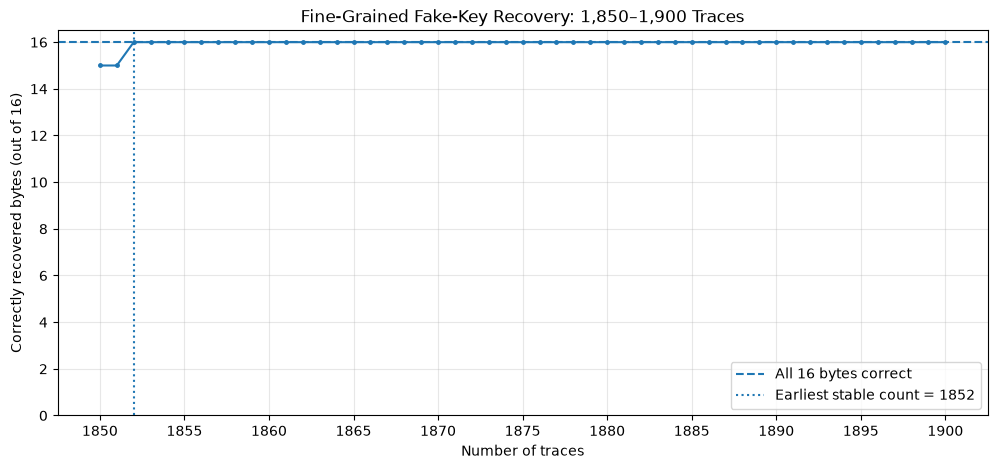

In [43]:
plt.figure(figsize=(12, 5))

plt.plot(
    fine_df["traces"],
    fine_df["correct_bytes"],
    marker=".",
    markersize=5
)

plt.axhline(16, linestyle="--", label="All 16 bytes correct")

if stable_minimum is not None:
    plt.axvline(
        stable_minimum,
        linestyle=":",
        label=f"Earliest stable count = {stable_minimum}"
    )

plt.xlabel("Number of traces")
plt.ylabel("Correctly recovered bytes (out of 16)")
plt.title("Fine-Grained Fake-Key Recovery: 1,850–1,900 Traces")
plt.xticks(range(START_N, END_N + 1, 5))
plt.ylim(0, 16.5)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [44]:
# Cell 10A: Shuffled full-window study

N_SHUFFLES = 100
RANDOM_SEED = 20261015

SHUFFLE_MIN_N = 500
SHUFFLE_MAX_N = 4000
SHUFFLE_STEP = 50

shuffle_checkpoints = list(
    range(SHUFFLE_MIN_N, SHUFFLE_MAX_N + 1, SHUFFLE_STEP)
)

rng = np.random.default_rng(RANDOM_SEED)

shuffle_tables = []
shuffle_stable_minima = []

shuffle_start = time.time()

for trial in range(N_SHUFFLES):
    print(f"\nShuffle {trial + 1}/{N_SHUFFLES}")

    # Random subset, in random order, without replacement.
    selected_indices = rng.permutation(N)[:SHUFFLE_MAX_N]

    results = run_all_bytes(
        checkpoints=shuffle_checkpoints,
        indices=selected_indices,
        sample_window=slice(0, 200),
        label=f"Trial {trial + 1}"
    )

    table = evaluate_checkpoints(
        results, shuffle_checkpoints, FAKE_KEY
    )
    table["trial"] = trial + 1
    shuffle_tables.append(table)

    success = table["all_16_correct"].to_numpy()
    counts = table["traces"].to_numpy()

    stable_n = None
    for i in range(len(counts)):
        if success[i:].all():
            stable_n = int(counts[i])
            break

    shuffle_stable_minima.append(stable_n)

shuffle_results_df = pd.concat(shuffle_tables, ignore_index=True)

print(
    f"\nFinished in {(time.time() - shuffle_start)/60:.1f} minutes."
)
print("Stable thresholds by trial:", shuffle_stable_minima)


Shuffle 1/100
Trial 1: byte 0/15
Trial 1: byte 1/15
Trial 1: byte 2/15
Trial 1: byte 3/15
Trial 1: byte 4/15
Trial 1: byte 5/15
Trial 1: byte 6/15
Trial 1: byte 7/15
Trial 1: byte 8/15
Trial 1: byte 9/15
Trial 1: byte 10/15
Trial 1: byte 11/15
Trial 1: byte 12/15
Trial 1: byte 13/15
Trial 1: byte 14/15
Trial 1: byte 15/15

Shuffle 2/100
Trial 2: byte 0/15
Trial 2: byte 1/15
Trial 2: byte 2/15
Trial 2: byte 3/15
Trial 2: byte 4/15
Trial 2: byte 5/15
Trial 2: byte 6/15
Trial 2: byte 7/15
Trial 2: byte 8/15
Trial 2: byte 9/15
Trial 2: byte 10/15
Trial 2: byte 11/15
Trial 2: byte 12/15
Trial 2: byte 13/15
Trial 2: byte 14/15
Trial 2: byte 15/15

Shuffle 3/100
Trial 3: byte 0/15
Trial 3: byte 1/15
Trial 3: byte 2/15
Trial 3: byte 3/15
Trial 3: byte 4/15
Trial 3: byte 5/15
Trial 3: byte 6/15
Trial 3: byte 7/15
Trial 3: byte 8/15
Trial 3: byte 9/15
Trial 3: byte 10/15
Trial 3: byte 11/15
Trial 3: byte 12/15
Trial 3: byte 13/15
Trial 3: byte 14/15
Trial 3: byte 15/15

Shuffle 4/100
Trial 4: b

In [45]:
# Cell 10B: Wilson confidence intervals for P(all 16 correct)

def wilson_interval(successes, trials, z=1.959963984540054):
    p = successes / trials
    denominator = 1 + z**2 / trials

    center = (
        p + z**2 / (2 * trials)
    ) / denominator

    half_width = (
        z * np.sqrt(
            p * (1 - p) / trials + z**2 / (4 * trials**2)
        ) / denominator
    )

    return max(0.0, center - half_width), min(1.0, center + half_width)


probability_rows = []

for n, group in shuffle_results_df.groupby("traces"):
    successes = int(group["all_16_correct"].sum())
    trials = len(group)
    lower, upper = wilson_interval(successes, trials)

    probability_rows.append({
        "traces": int(n),
        "successes": successes,
        "trials": trials,
        "p_all_16_correct": successes / trials,
        "ci95_low": lower,
        "ci95_high": upper
    })

full_probability_df = pd.DataFrame(
    probability_rows
).sort_values("traces")

display(full_probability_df)

,traces,successes,trials,p_all_16_correct,ci95_low,ci95_high
0,500,0,100,0.0,3.469447e-18,0.036993
1,550,0,100,0.0,3.469447e-18,0.036993
2,600,0,100,0.0,3.469447e-18,0.036993
3,650,0,100,0.0,3.469447e-18,0.036993
4,700,0,100,0.0,3.469447e-18,0.036993
...,...,...,...,...,...,...
66,3800,100,100,1.0,9.630065e-01,1.000000
67,3850,100,100,1.0,9.630065e-01,1.000000
68,3900,100,100,1.0,9.630065e-01,1.000000
69,3950,100,100,1.0,9.630065e-01,1.000000


In [47]:
# Smallest N from which P(all 16 correct) stays >= target for every larger N in the table
def headline_n(df, target):
    df = df.sort_values("traces").reset_index(drop=True)
    ok = (df["p_all_16_correct"] >= target).to_numpy()
    bad = np.where(~ok)[0]
    i = 0 if len(bad) == 0 else bad[-1] + 1
    return None if i >= len(df) else df.iloc[i]

for target in (0.90, 0.95):
    row = headline_n(full_probability_df, target)
    if row is None:
        print(f"{target:.0%}: not reached in the tested range")
    else:
        print(f"{target:.0%} success: N = {int(row['traces'])} "
              f"(P = {row['p_all_16_correct']:.2f}, "
              f"95% CI [{row['ci95_low']:.2f}, {row['ci95_high']:.2f}], "
              f"{int(row['trials'])} trials)")

90% success: N = 2650 (P = 0.90, 95% CI [0.83, 0.94], 100 trials)
95% success: N = 2800 (P = 0.95, 95% CI [0.89, 0.98], 100 trials)


In [48]:
valid = [x for x in shuffle_stable_minima if x is not None]
print(f"Original order, stable from: {stable_minimum} traces (1-trace resolution)")
print(f"Shuffled trials with stable recovery: {len(valid)}/{len(shuffle_stable_minima)}")
if valid:
    print(f"Per-trial stable minimum: median {int(np.median(valid))}, "
          f"90th percentile {int(np.percentile(valid, 90))}, max {max(valid)}")

Original order, stable from: 1852 traces (1-trace resolution)
Shuffled trials with stable recovery: 100/100
Per-trial stable minimum: median 2150, 90th percentile 2750, max 3200


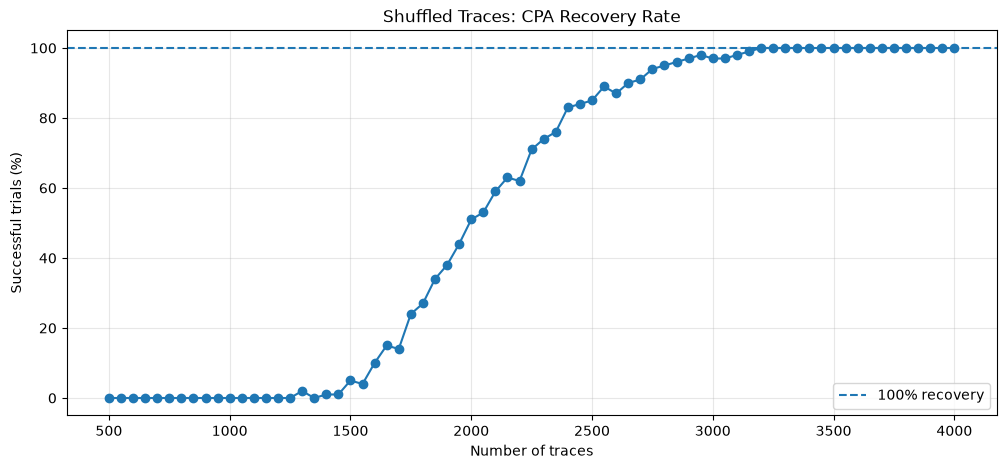

In [49]:
# Cell 12: Recovery rate across shuffled trials

shuffle_success_rate = (
    shuffle_results_df
    .groupby("traces")["all_16_correct"]
    .mean()
)

plt.figure(figsize=(12, 5))

plt.plot(
    shuffle_success_rate.index,
    shuffle_success_rate.values * 100,
    marker="o"
)

plt.axhline(100, linestyle="--", label="100% recovery")

plt.xlabel("Number of traces")
plt.ylabel("Successful trials (%)")
plt.title("Shuffled Traces: CPA Recovery Rate")
plt.ylim(-5, 105)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [32]:
# Cell: Compare the three adjacent trace counts

import numpy as np
import pandas as pd

TEST_COUNTS = [1851, 1852, 1853]

T_test = np.asarray(
    traces[:max(TEST_COUNTS), SAMPLE_WINDOW],
    dtype=np.float64
)

comparison_rows = []
recovered_keys = {}

with np.load(HYPOTHESES_PATH) as hypotheses:
    for b in range(16):
        H = np.asarray(hypotheses[f"byte_{b}"])

        # Normalize to (N, 256)
        if H.shape[0] == 256 and H.shape[1] >= max(TEST_COUNTS):
            H = H.T

        assert H.shape[0] >= max(TEST_COUNTS)
        assert H.shape[1] == 256

        H = H.astype(np.float64)

        for n in TEST_COUNTS:
            scores = cpa_scores(H[:n], T_test[:n])

            ranking = np.argsort(scores)[::-1]
            expected = int(FAKE_KEY[b])
            winner = int(ranking[0])

            correct_rank = int(
                np.where(ranking == expected)[0][0] + 1
            )

            recovered_keys.setdefault(n, np.zeros(16, dtype=np.uint8))
            recovered_keys[n][b] = winner

            comparison_rows.append({
                "traces": n,
                "byte": b,
                "expected": f"{expected:02X}",
                "winner": f"{winner:02X}",
                "correct_rank": correct_rank,
                "correct_byte": winner == expected,
                "top_score": float(scores[ranking[0]]),
                "correct_score": float(scores[expected]),
                "top_is_unique": bool(
                    np.sum(np.isclose(scores, scores[ranking[0]])) == 1
                )
            })

comparison_df = pd.DataFrame(comparison_rows)

summary_rows = []

for n in TEST_COUNTS:
    subset = comparison_df[comparison_df["traces"] == n]
    key = recovered_keys[n]

    summary_rows.append({
        "traces": n,
        "correct_bytes": int(subset["correct_byte"].sum()),
        "all_16_correct": bool(np.array_equal(key, FAKE_KEY)),
        "all_winners_unique": bool(subset["top_is_unique"].all()),
        "recovered_key": " ".join(f"{x:02X}" for x in key)
    })

summary_df = pd.DataFrame(summary_rows)

display(summary_df)

,traces,correct_bytes,all_16_correct,all_winners_unique,recovered_key
0,1851,15,False,True,02 DE C0 68 E3 FA CE 45 99 CE 38 F4 20 86 3A 30
1,1852,16,True,True,91 DE C0 68 E3 FA CE 45 99 CE 38 F4 20 86 3A 30
2,1853,16,True,True,91 DE C0 68 E3 FA CE 45 99 CE 38 F4 20 86 3A 30
